In [1]:
# Cell 1: Load industry-standard analytics & AI libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

# Set clean aesthetic styling for our charts
sns.set_theme(style="whitegrid")
print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Cell 2: Load the official 500-transaction supermarket dataset
dataset_url = "https://docs.google.com/spreadsheets/d/1QIX__4VObHFMEXnRM2xJyXmB5JAB2peHrJcQ41_U9TE/export?format=csv"
df = pd.read_csv(dataset_url)

# Display basic structural dimensions
print(f"Total Transactions: {df.shape[0]} rows")
print(f"Total Features: {df.shape[1]} columns")
df.head(5)

Total Transactions: 500 rows
Total Features: 13 columns


,Invoice ID,Date,Branch,City,Customer Type,Gender,Product,Category,Quantity,Unit Price,Payment,Rating,Sales
0,INV0001,2026-06-01,A,Jaipur,Member,Male,Milk,Dairy,4,57.13,UPI,3.8,228.52
1,INV0002,2026-02-26,A,Jaipur,Normal,Male,Rice,Grocery,9,66.85,Net Banking,3.9,601.65
2,INV0003,2026-02-09,C,Mumbai,Normal,Female,Milk,Dairy,3,57.28,Card,3.4,171.84
3,INV0004,2026-01-12,C,Mumbai,Member,Female,Shampoo,Personal Care,2,168.27,Card,4.5,336.54
4,INV0005,2026-06-30,A,Jaipur,Normal,Female,Apples,Fruits,5,130.57,Cash,3.1,652.85


In [3]:
# Cell 3: Data integrity checks
print("--- Missing Values Check ---")
print(df.isnull().sum())

# Ensure Sales column exists and is calculated precisely
df['Sales'] = df['Quantity'] * df['Unit Price']

print("\n--- Summary Statistics ---")
display(df.describe())

--- Missing Values Check ---
Invoice ID       0
Date             0
Branch           0
City             0
Customer Type    0
Gender           0
Product          0
Category         0
Quantity         0
Unit Price       0
Payment          0
Rating           0
Sales            0
dtype: int64

--- Summary Statistics ---


,Quantity,Unit Price,Rating,Sales
count,500.000000,500.000000,500.000000,500.000000
mean,5.536000,88.660700,3.994400,488.822160
std,2.875629,57.284029,0.574481,437.327833
min,1.000000,27.670000,3.000000,28.610000
25%,3.000000,43.955000,3.500000,189.212500
50%,5.500000,61.880000,4.000000,335.910000
75%,8.000000,128.567500,4.500000,609.885000
max,10.000000,236.710000,5.000000,2114.820000


Sales by Branch:
   Branch     Sales
0      A  52357.08
1      B  64116.26
2      C  72469.45
3      D  55468.29


/tmp/ipykernel_4963/437007609.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=branch_perf, x='Branch', y='Sales', palette='Blues_d')


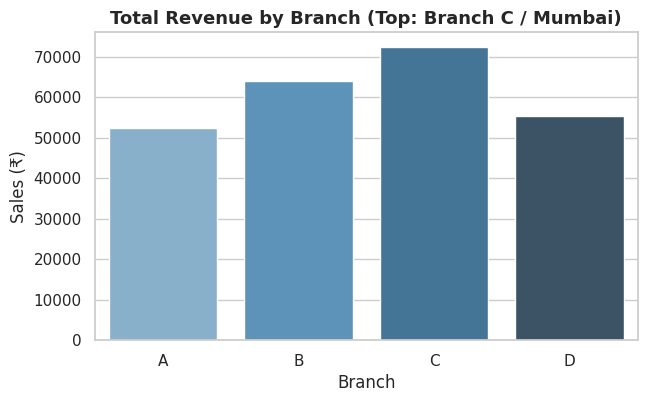

/tmp/ipykernel_4963/437007609.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=category_perf, x='Category', y='Sales', palette='viridis')


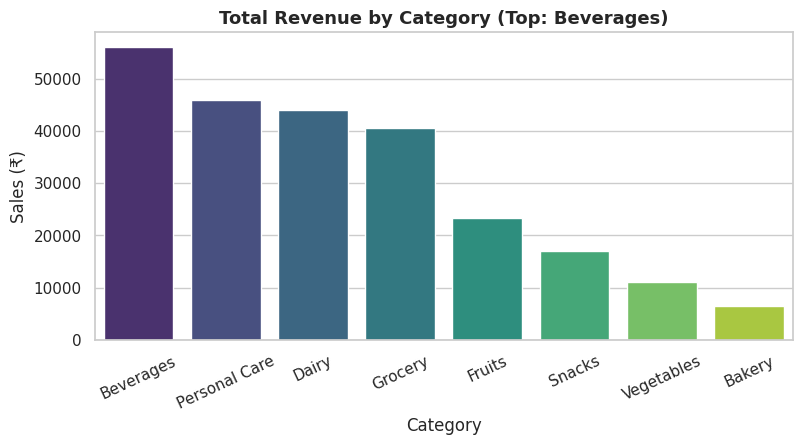

/tmp/ipykernel_4963/437007609.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Payment', palette='magma', order=df['Payment'].value_counts().index)


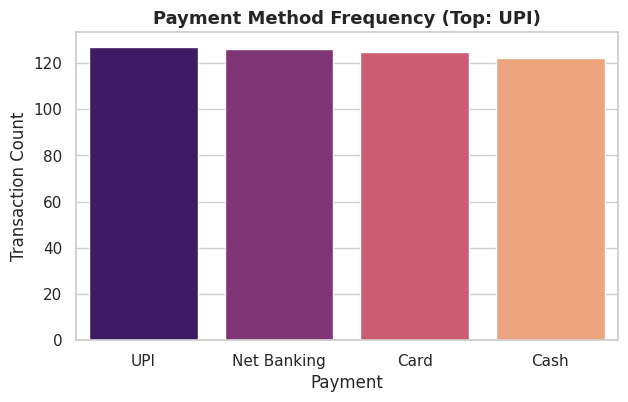

/tmp/ipykernel_4963/437007609.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=member_comp, x='Customer Type', y='Sales', palette='Set2')



Average Spend Comparison:
   Customer Type       Sales
0        Member  483.139527
1        Normal  497.067549


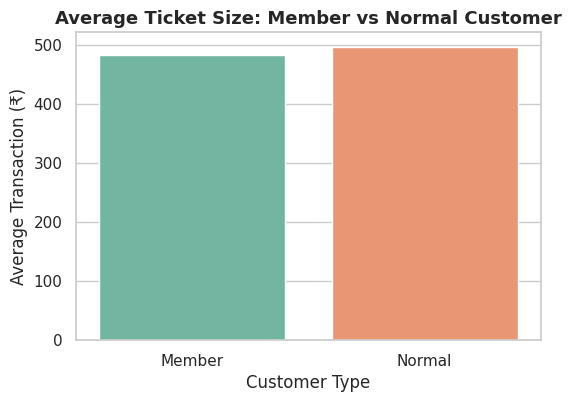

In [4]:
# Cell 4: Business Exploratory Data Analysis

# 1. Best Performing Branch
branch_perf = df.groupby('Branch')['Sales'].sum().reset_index()
print("Sales by Branch:\n", branch_perf)

plt.figure(figsize=(7, 4))
sns.barplot(data=branch_perf, x='Branch', y='Sales', palette='Blues_d')
plt.title('Total Revenue by Branch (Top: Branch C / Mumbai)', fontsize=13, fontweight='bold')
plt.ylabel('Sales (₹)')
plt.show()

# 2. Sales by Product Category
category_perf = df.groupby('Category')['Sales'].sum().sort_values(ascending=False).reset_index()

plt.figure(figsize=(9, 4))
sns.barplot(data=category_perf, x='Category', y='Sales', palette='viridis')
plt.title('Total Revenue by Category (Top: Beverages)', fontsize=13, fontweight='bold')
plt.xticks(rotation=25)
plt.ylabel('Sales (₹)')
plt.show()

# 3. Preferred Payment Method
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x='Payment', palette='magma', order=df['Payment'].value_counts().index)
plt.title('Payment Method Frequency (Top: UPI)', fontsize=13, fontweight='bold')
plt.ylabel('Transaction Count')
plt.show()

# 4. Member vs Normal Customer Average Spend
member_comp = df.groupby('Customer Type')['Sales'].mean().reset_index()
print("\nAverage Spend Comparison:\n", member_comp)

plt.figure(figsize=(6, 4))
sns.barplot(data=member_comp, x='Customer Type', y='Sales', palette='Set2')
plt.title('Average Ticket Size: Member vs Normal Customer', fontsize=13, fontweight='bold')
plt.ylabel('Average Transaction (₹)')
plt.show()

Model Performance:
R² Score: 0.421
RMSE: ₹291.68


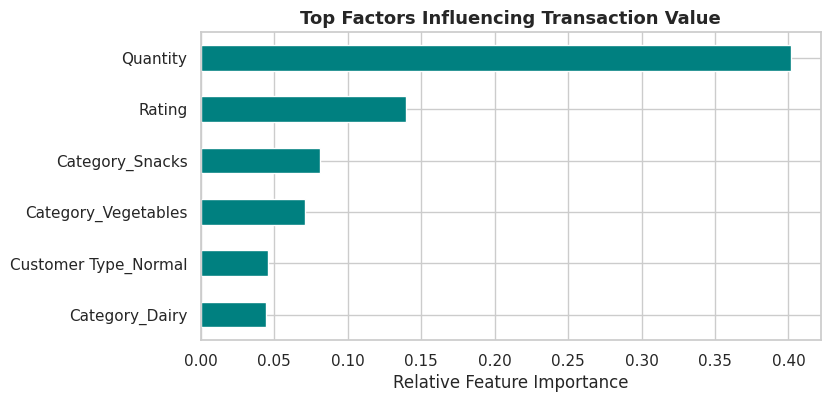

In [5]:
# Cell 5: Machine Learning - Predicting Transaction Sales

# Select feature columns and target
feature_cols = ['Branch', 'Category', 'Customer Type', 'Payment', 'Quantity', 'Rating']
target_col = 'Sales'

# Convert text/categorical columns into numerical representations using One-Hot Encoding
X = pd.get_dummies(df[feature_cols], drop_first=True)
y = df[target_col]

# Split 80% data for training, 20% for testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

# Initialize and train the Random Forest AI model
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# Evaluate predictions
y_pred = model.predict(X_test)
r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print(f"Model Performance:")
print(f"R² Score: {r2:.3f}")
print(f"RMSE: ₹{rmse:.2f}")

# Extract and plot Feature Importances
importances = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(8, 4))
importances.head(6).plot(kind='barh', color='teal')
plt.title('Top Factors Influencing Transaction Value', fontsize=13, fontweight='bold')
plt.xlabel('Relative Feature Importance')
plt.gca().invert_yaxis()
plt.show()